# CNN: combinar lo que funcionó

En la ronda 1 se probó un factor a la vez (25 épocas, 1 semilla) y se vio que la red estaba subentrenada: ayudó lo que facilita optimizar (lr más bajo, conexiones residuales, más profundidad) y perjudicó lo que regulariza. Aquí se combinan esas mejoras y se entrena más tiempo 40 épocas.

### Qué se prueba

Todas parten de `lr = 3e-4` la ganadora de la ronda 1 con aumentos `mid`:

| Configuración | Qué lleva | Qué pregunta responde |
|---|---|---|
| ref_lr3e-4 | Solo lr 3e-4 | Referencia: ¿cuánto mejora con 40 épocas en vez de 25? |
| lr3e-4_res | + conexiones residuales | ¿Se suman? |
| lr3e-4_b5 | + 5 bloques | ¿Se suman? |
| lr3e-4_res_b5 | + residual + 5 bloques | ¿Se suman los tres? |
| lr1e-4_res_b5 | lr 1e-4 + residual + 5 bloques | ¿Un lr aún más bajo ayuda? (3e-4 quedó en el borde de lo probado) |

## Reglas

- Mismo split que todo el proyecto.** Solo se leen `train` y `valid`; `test` nunca se cargan.

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageOps
from sklearn.metrics import confusion_matrix, f1_score
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T

## 1. Parámetros fijos

In [2]:
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CLAUDE.md').is_file())
CROPS_CSV = ROOT / 'data/crops/crops.csv'
OUT_DIR = ROOT / 'dl/outputs/cnn_combos'
ROUND1_DIR = ROOT / 'dl/outputs/cnn'
CLASSES = ['ascaris', 'hookworm', 'trichuris']

SEED = 42
EPOCHS = 40
PATIENCE = 10         
BATCH = 32
IMG_SIZE = 224
WEIGHT_DECAY = 1e-2
LABEL_SMOOTHING = 0.1
MIXUP_ALPHA = 0.4
TRAIN_EVAL_SIZE = 500   
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
NUM_WORKERS = min(8, len(os.sched_getaffinity(0)))
print('device:', torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'cpu', '| workers:', NUM_WORKERS)
assert CROPS_CSV.is_file(), f'missing {CROPS_CSV}: run data_prep/src/crop_eggs.py first'

device: NVIDIA H100 NVL | workers: 8


## 2. Las configuraciones

In [3]:
BASE = dict(blocks=4, width=32, residual=False, dropout=0.3, lr=3e-4, aug='mid', mixup=False)
REF = 'ref_lr3e-4'

CHANGES = {
    REF: {},
    'lr3e-4_res': dict(residual=True),
    'lr3e-4_b5': dict(blocks=5),
    'lr3e-4_res_b5': dict(residual=True, blocks=5),
    'lr1e-4_res_b5': dict(residual=True, blocks=5, lr=1e-4),
}
CONFIGS = {name: {**BASE, **changes} for name, changes in CHANGES.items()}

AUG = {
    'low': dict(color=0.1, blur=0.0, noise=0.0),
    'mid': dict(color=0.3, blur=0.3, noise=0.3),
    'high': dict(color=0.5, blur=0.5, noise=0.5),
}
pd.DataFrame(CONFIGS).T

,blocks,width,residual,dropout,lr,aug,mixup
ref_lr3e-4,4,32,False,0.3,0.0003,mid,False
lr3e-4_res,4,32,True,0.3,0.0003,mid,False
lr3e-4_b5,5,32,False,0.3,0.0003,mid,False
lr3e-4_res_b5,5,32,True,0.3,0.0003,mid,False
lr1e-4_res_b5,5,32,True,0.3,0.0001,mid,False


**Ronda 2: combinaciones.** En la ronda 1 lo que más ayudó fue bajar el learning rate (3e-4), añadir un quinto bloque y, en menor medida, las conexiones residuales. Aquí se prueban esos factores juntos durante 40 épocas, porque un experimento de un factor a la vez no dice si sus efectos se suman. Se mantienen fijos `width` 32, `dropout` 0,3, aumentos `mid` y sin mixup. Las cuatro primeras configuraciones forman una cuadrícula 2×2 (residual sí/no × 4 o 5 bloques) con lr 3e-4, y `ref_lr3e-4` es la referencia: la mejor de la ronda 1 entrenada 40 épocas en vez de 25. La última, `lr1e-4_res_b5`, repite la combinación más grande con un lr menor para ver si es más estable. Cada configuración usa una sola semilla, así que las diferencias pequeñas pueden ser ruido.


## 3. Datos

In [4]:
def pad_to_square(img):
    side = max(img.size)
    fill = tuple(int(c) for c in np.asarray(img).reshape(-1, 3).mean(axis=0))
    return ImageOps.pad(img, (side, side), color=fill, centering=(0.5, 0.5))


def dihedral(img):
    img = img.rotate(90 * random.randrange(4))
    return ImageOps.mirror(img) if random.random() < 0.5 else img


class AddNoise:
    def __init__(self, p, max_std=0.05):
        self.p, self.max_std = p, max_std

    def __call__(self, x):
        if random.random() < self.p:
            x = x + torch.randn_like(x) * random.uniform(0.01, self.max_std)
        return x.clamp(0, 1)


def make_transform(aug=None):
    steps = [T.Resize((IMG_SIZE, IMG_SIZE), interpolation=T.InterpolationMode.BICUBIC)]
    if aug is not None:
        a = AUG[aug]
        steps += [
            T.Lambda(dihedral),
            T.ColorJitter(a['color'], a['color'], a['color'], a['color'] * 0.1),
            T.RandomApply([T.GaussianBlur(5, sigma=(0.5, 2.0))], p=a['blur']),
        ]
    steps.append(T.ToTensor())
    if aug is not None:
        steps.append(AddNoise(a['noise']))
    steps.append(T.Normalize(MEAN, STD))
    return T.Compose(steps)


class Crops(Dataset):
    def __init__(self, images, labels, aug=None):
        self.images, self.labels, self.tf = images, labels, make_transform(aug)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.tf(self.images[i]), self.labels[i]


df = pd.read_csv(CROPS_CSV)
df = df[df['split'].isin(['train', 'valid'])]  
assert 'test' not in set(df['split'])


def load(split):
    part = df[df['split'] == split]
    images = [pad_to_square(Image.open(ROOT / p).convert('RGB')) for p in part['crop_path']]
    return images, [CLASSES.index(label) for label in part['label']]


train_imgs, train_y = load('train')
valid_imgs, valid_y = load('valid')
df.groupby(['split', 'label']).size().unstack()

label,ascaris,hookworm,trichuris
split,,,
train,636,650,638
valid,136,140,137


In [5]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_loader(images, labels, aug, shuffle):
    g = torch.Generator()
    g.manual_seed(SEED)
    return DataLoader(Crops(images, labels, aug), batch_size=BATCH, shuffle=shuffle, drop_last=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == 'cuda'),
                      persistent_workers=NUM_WORKERS > 0, generator=g)

subset = np.random.RandomState(0).choice(len(train_y), TRAIN_EVAL_SIZE, replace=False)
train_eval_loader = make_loader([train_imgs[i] for i in subset], [train_y[i] for i in subset], None, shuffle=False)
valid_loader = make_loader(valid_imgs, valid_y, None, shuffle=False)

## 4. La red

La misma de la ronda 1. Cada **bloque** son dos convoluciones 3×3 con BatchNorm y ReLU, y un `MaxPool` que reduce la imagen a la mitad; los canales se duplican en cada bloque. Al final: promedio global, `Dropout` y una capa lineal con 3 salidas. Con `residual=True`, cada bloque suma un atajo (convolución 1×1) de su entrada a su salida.

In [6]:
class Block(nn.Module):
    def __init__(self, cin, cout, residual):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
        self.conv2 = nn.Sequential(nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout))
        self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, bias=False), nn.BatchNorm2d(cout)) if residual else None
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        out = self.conv2(self.conv1(x))
        if self.skip is not None:
            out = out + self.skip(x)
        return self.pool(F.relu(out))


class CNN(nn.Module):
    def __init__(self, blocks, width, residual, dropout, n_classes=3):
        super().__init__()
        chans = [3] + [width * 2 ** i for i in range(blocks)]
        self.features = nn.Sequential(*[Block(chans[i], chans[i + 1], residual) for i in range(blocks)])
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(dropout), nn.Linear(chans[-1], n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def build_model(cfg):
    return CNN(cfg['blocks'], cfg['width'], cfg['residual'], cfg['dropout'])


pd.Series({name: sum(p.numel() for p in build_model(cfg).parameters()) for name, cfg in CONFIGS.items()}, name='parameters')

ref_lr3e-4       1173987
lr3e-4_res       1218051
lr3e-4_b5        4715747
lr3e-4_res_b5    4891907
lr1e-4_res_b5    4891907
Name: parameters, dtype: int64

**Tamaño de las redes.** Añadir conexiones residuales cuesta muy poco (+44.064 parámetros, +3,8 %): solo son las convoluciones 1×1 y BatchNorm de los atajos. En cambio, pasar de 4 a 5 bloques multiplica el tamaño por ~4 (de 1,17 M a 4,72 M), porque cada bloque duplica los canales y el quinto (256 → 512) aporta ~3,5 M parámetros, aunque solo añada dos capas convolucionales. El learning rate no cambia el tamaño, por lo que `lr3e-4_res_b5` y `lr1e-4_res_b5` tienen los mismos 4,89 M. Incluso la red más grande (~19 MB en float32) es liviana para un uso offline.


## 5. Entrenamiento

El entrenamiento se realiza con los datos fijados anteriormente y un cambio para cada configuraciónm asi mismo utilizamos:  **AdamW** como optimizador, el cual adapta el tamaño del paso de acuerdo a cada peso, aqui enta el weight decay,  programación **coseno** para el learning rate que baja a ~0 en la última época, y parada temprana por **F1 macro en `valid`** si entre las 3 clases no se supera la anterior por 10 epocas. Se guarda el peso de la mejor época.

Si el job se corta a mitad de una configuración, esa se vuelve a entrenar desde cero al relanzar; las ya terminadas se reutilizan.

In [7]:
def evaluate(model, loader):
    model.eval()
    total, preds, ys = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            total += F.cross_entropy(out, y, reduction='sum').item()   # plain loss, no smoothing
            preds.append(out.argmax(1).cpu())
            ys.append(y.cpu())
    preds, ys = torch.cat(preds).numpy(), torch.cat(ys).numpy()
    return total / len(ys), preds, ys


def train_run(name, cfg):
    run_dir = OUT_DIR / name
    if (run_dir / 'done.json').is_file():
        print(f'{name}: already trained, reused')
        return
    run_dir.mkdir(parents=True, exist_ok=True)
    (run_dir / 'config.json').write_text(json.dumps(cfg, indent=2))

    set_seed(SEED)
    model = build_model(cfg).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters())
    opt = torch.optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    crit = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
    train_loader = make_loader(train_imgs, train_y, cfg['aug'], shuffle=True)

    history, best_f1, best_epoch, start = [], -1.0, 0, time.time()
    for epoch in range(1, EPOCHS + 1):
        model.train()
        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            if cfg['mixup']:
                lam = float(np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA))
                perm = torch.randperm(len(x), device=DEVICE)
                out = model(lam * x + (1 - lam) * x[perm])
                loss = lam * crit(out, y) + (1 - lam) * crit(out, y[perm])
            else:
                loss = crit(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        sched.step()

        tr_loss, tr_pred, tr_true = evaluate(model, train_eval_loader)
        va_loss, va_pred, va_true = evaluate(model, valid_loader)
        row = dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss,
                   train_f1=f1_score(tr_true, tr_pred, average='macro'),
                   val_f1=f1_score(va_true, va_pred, average='macro'))
        history.append(row)
        if row['val_f1'] > best_f1:
            best_f1, best_epoch = row['val_f1'], epoch
            torch.save(model.state_dict(), run_dir / 'best.pt')
        val_f1 = row['val_f1']
        minutes = (time.time() - start) / 60
        print(f'{name} | epoch {epoch:2d}/{EPOCHS} | val F1 {val_f1:.4f} (best {best_f1:.4f}) | {minutes:.1f} min')
        if epoch - best_epoch >= PATIENCE:
            print(f'{name}: early stop at epoch {epoch}')
            break

    pd.DataFrame(history).to_csv(run_dir / 'history.csv', index=False)
    summary = dict(best_epoch=best_epoch, best_val_f1=best_f1, n_params=n_params, epochs_run=len(history),
                   minutes=round((time.time() - start) / 60, 2), device=DEVICE)
    (run_dir / 'done.json').write_text(json.dumps(summary, indent=2))

In [8]:
for name, cfg in CONFIGS.items():
    train_run(name, cfg)

ref_lr3e-4: already trained, reused
lr3e-4_res: already trained, reused
lr3e-4_b5: already trained, reused
lr3e-4_res_b5: already trained, reused
lr1e-4_res_b5: already trained, reused


## 6. Resultados

In [9]:
rows, histories = [], {}
for name in CONFIGS:
    done = json.loads((OUT_DIR / name / 'done.json').read_text())
    histories[name] = pd.read_csv(OUT_DIR / name / 'history.csv')
    best = histories[name].iloc[done['best_epoch'] - 1]
    rows.append({'run': name, 'parameters': done['n_params'], 'best_epoch': done['best_epoch'],
                 'epochs_run': done['epochs_run'], 'train_f1': best['train_f1'], 'val_f1': best['val_f1'],
                 'gap': best['train_f1'] - best['val_f1'], 'minutes': done['minutes']})
results = pd.DataFrame(rows).set_index('run')
results.sort_values('val_f1', ascending=False).round(4)

,parameters,best_epoch,epochs_run,train_f1,val_f1,gap,minutes
run,,,,,,,
lr3e-4_b5,4715747,37,40,0.9922,0.9782,0.0140,47.23
lr3e-4_res_b5,4891907,27,37,0.9707,0.9709,-0.0002,59.47
lr1e-4_res_b5,4891907,38,40,0.9820,0.9635,0.0186,65.35
ref_lr3e-4,1173987,36,40,0.9494,0.9562,-0.0069,51.50
lr3e-4_res,1218051,37,40,0.9411,0.9317,0.0095,66.96


**Resultados de la ronda 2 .** La mejor configuración es `lr3e-4_b5` (F1 macro en `valid` de 0,9782). Entrenar más ya aporta por sí solo: `ref_lr3e-4`, que con 25 épocas obtuvo 0,9027, llega a 0,9562 con 40. Un quinto bloque suma otros +0,022. Las conexiones residuales no ayudan: con 4 bloques empeoran (0,9317 frente a 0,9562) y con 5 quedan ligeramente por debajo (0,9709 frente a 0,9782, una diferencia pequeña que podría ser ruido). Bajar el learning rate a 1e-4 tampoco mejora (0,9635). Los `gap` son pequeños (entre −0,007 y +0,019), sin sobreajuste fuerte. Cuatro de las cinco configuraciones tienen su mejor época entre la 36 y la 38, es decir, seguían mejorando al terminar; por eso la corrida final usa 100 épocas. 


### ¿Cuánto es ruido?

Cada configuración se entrenó con **una sola semilla**. Se calcula un intervalo de 95 % para el F1 de la **referencia** (`ref_lr3e-4`) remuestreando los recortes de `valid` (*bootstrap*, 1000 veces). Una configuración dentro de esa franja **no se distingue de la referencia**.

ref_lr3e-4: val F1 0.9562, 95% interval [0.9362, 0.9747]


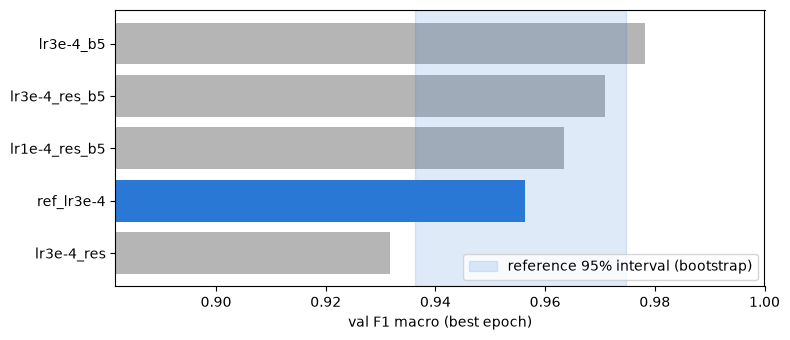

In [10]:
def load_model(name):
    model = build_model(CONFIGS[name]).to(DEVICE)
    model.load_state_dict(torch.load(OUT_DIR / name / 'best.pt', map_location=DEVICE))
    return model


_, ref_pred, ref_true = evaluate(load_model(REF), valid_loader)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    idx = rng.integers(0, len(ref_true), len(ref_true))
    boot.append(f1_score(ref_true[idx], ref_pred[idx], average='macro'))
low, high = np.percentile(boot, [2.5, 97.5])
ref_f1 = results.loc[REF, 'val_f1']
print(f'{REF}: val F1 {ref_f1:.4f}, 95% interval [{low:.4f}, {high:.4f}]')

order = results['val_f1'].sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(order.index, order.values, color=['#2a78d6' if n == REF else '#b5b5b5' for n in order.index])
ax.axvspan(low, high, color='#2a78d6', alpha=0.15, label='reference 95% interval (bootstrap)')
ax.set(xlim=(max(0, order.min() - 0.05), 1.0), xlabel='val F1 macro (best epoch)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### Curvas

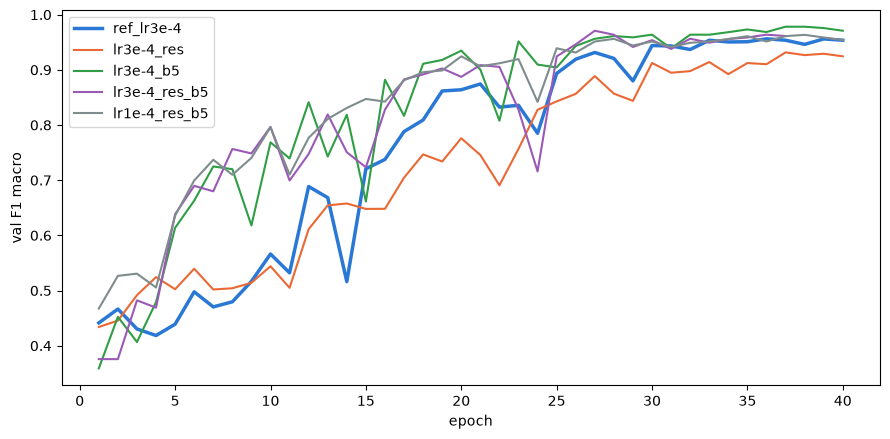

In [11]:
palette = ['#2a78d6', '#eb6834', '#2f9e44', '#9b59b6', '#7f8c8d']
fig, ax = plt.subplots(figsize=(9, 4.5))
for color, (name, h) in zip(palette, histories.items()):
    ax.plot(h['epoch'], h['val_f1'], color=color, lw=2.5 if name == REF else 1.5, label=name)
ax.set(xlabel='epoch', ylabel='val F1 macro')
ax.legend()
plt.tight_layout()
plt.show()

**Curvas de la ronda 2 (F1 macro en `valid`).** Las tres configuraciones con 5 bloques aprenden más rápido: alcanzan 0,7 hacia la época 6–8, mientras que las de 4 bloques tardan hasta la época 15–20. Las curvas son ruidosas al principio (por ejemplo, caídas bruscas de `ref_lr3e-4` en la época 14 y de `lr3e-4_res_b5` en la 24) y se estabilizan a partir de la época ~30, donde las cuatro mejores quedan entre ~0,95 y ~0,98 y sus diferencias son menores que el ruido anterior. Solo `lr3e-4_res` se queda claramente por debajo 0,92. Ninguna curva se aplana por completo en la época 40, lo que justifica entrenar más tiempo en la corrida final. Dado que las configuraciones con 5 bloques terminan parecidas, se elige `lr3e-4_b5` por ser la de mejor F1 final, la más simple (sin residual) y la más rápida por época.


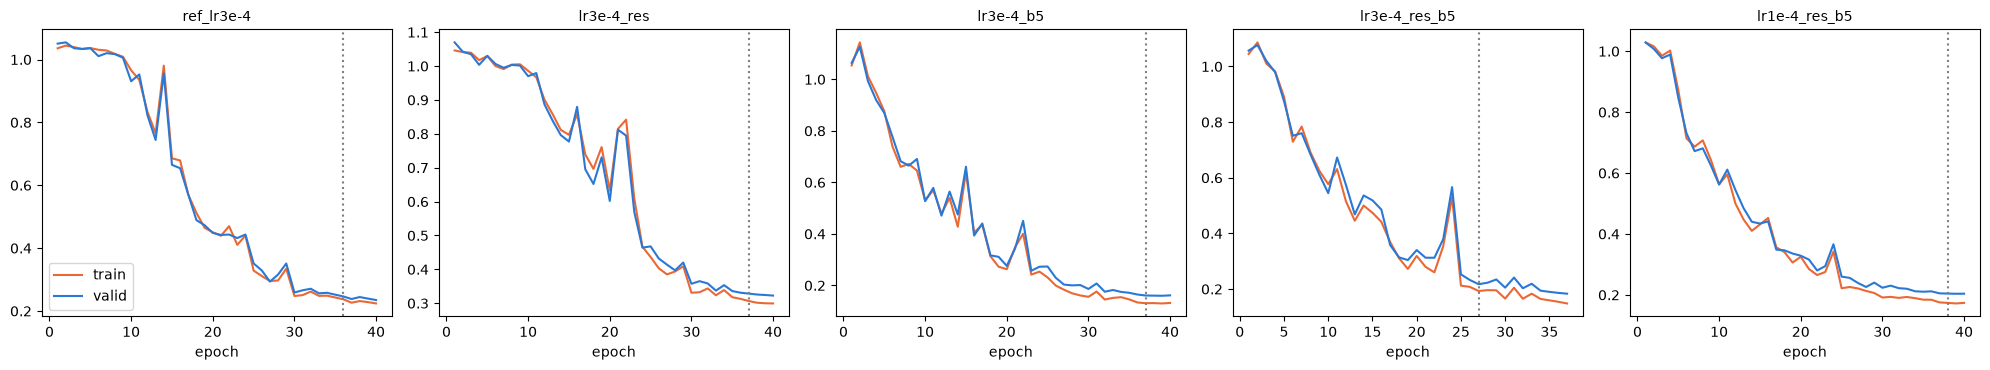

In [12]:
fig, axes = plt.subplots(1, len(histories), figsize=(4 * len(histories), 3.8), squeeze=False)
for ax, (name, h) in zip(axes[0], histories.items()):
    ax.plot(h['epoch'], h['train_loss'], color='#eb6834', label='train')
    ax.plot(h['epoch'], h['val_loss'], color='#2a78d6', label='valid')
    ax.axvline(results.loc[name, 'best_epoch'], color='gray', ls=':')
    ax.set_title(name, fontsize=10)
    ax.set_xlabel('epoch')
axes[0, 0].legend()
plt.tight_layout()
plt.show()

**Curvas de pérdida de la ronda 2 (train en naranja, valid en azul; la línea punteada marca la mejor época).** La pérdida es la entropía cruzada sin suavizado de etiquetas, y cada panel tiene su propia escala vertical. Todas bajan desde ~1,1 azar con 3 clases hasta ~0,13–0,33. Las tres configuraciones con 5 bloques terminan más abajo (~0,13–0,20) que las de 4 bloques (~0,23 y ~0,30), en el mismo orden que el F1. Train y valid van juntas; solo en `lr3e-4_b5` y `lr1e-4_res_b5` se abre una brecha pequeña al final, coherente con sus gaps de +0,014 y +0,019. Los picos (por ejemplo, en la época 14 de `ref_lr3e-4` y en la 24 de `lr3e-4_res_b5`) coinciden con las caídas de F1 y son inestabilidades temporales de las que la red se recupera. Al terminar, las curvas son casi planas.


## 7. La finalista

La de mayor F1 en `valid`, y cuáles otras **no se distinguen** de la referencia según el intervalo de arriba. Con 1 semilla, si varias quedan empatadas, la elección se hace con las 3 semillas de la ronda final.

In [13]:
best_name = results['val_f1'].idxmax()
best_f1 = results.loc[best_name, 'val_f1']
inside = [n for n in results.index if low <= results.loc[n, 'val_f1'] <= high]
print('best on valid:', best_name, f'(F1 {best_f1:.4f})')
print('inside the reference interval (not distinguishable from it):', inside)

_, pred, true = evaluate(load_model(best_name), valid_loader)
cm = confusion_matrix(true, pred)
print('\nconfusion matrix on valid (rows = true, columns = predicted)')
display(pd.DataFrame(cm, index=CLASSES, columns=CLASSES))
print('recall per class:', dict(zip(CLASSES, (cm.diagonal() / cm.sum(axis=1)).round(4))))
CONFIGS[best_name]

best on valid: lr3e-4_b5 (F1 0.9782)
inside the reference interval (not distinguishable from it): ['ref_lr3e-4', 'lr3e-4_res_b5', 'lr1e-4_res_b5']

confusion matrix on valid (rows = true, columns = predicted)


,ascaris,hookworm,trichuris
ascaris,133,0,3
hookworm,2,137,1
trichuris,3,0,134


recall per class: {'ascaris': np.float64(0.9779), 'hookworm': np.float64(0.9786), 'trichuris': np.float64(0.9781)}


{'blocks': 5,
 'width': 32,
 'residual': False,
 'dropout': 0.3,
 'lr': 0.0003,
 'aug': 'mid',
 'mixup': False}

**Matriz de confusión (`valid`, 413 recortes; filas = clase real, columnas = clase predicha).** Se clasifican bien 404 de 413 recortes (accuracy 0,978). El recall es parejo entre clases: ascaris 0,978 (133/136), hookworm 0,979 (137/140) y trichuris 0,978 (134/137). La confusión principal es entre ascaris y trichuris (6 de los 9 errores, 3 en cada sentido). Hookworm nunca se predice por error (precisión 1,000): sus 3 errores son huevos de hookworm que la red asigna a otra clase. Con 9 errores en total, un recorte cambia el F1 en ~0,002, por lo que diferencias de ese orden entre configuraciones no son concluyentes.
